# YOLO, first steps — on your own photos

**What YOLO does:** you give it a photo, it gives back a list of **boxes**. Each box has
- a **class** (what it is: "exit sign"),
- a **confidence** from 0 to 1 (how sure it is),
- **coordinates** in pixels `[x1, y1, x2, y2]` (top-left and bottom-right corners).

There are two kinds you will use:

| | Knows | You change it by |
| --- | --- | --- |
| **YOLO26** (normal YOLO, 2026) | 80 everyday classes it was trained on (person, chair, tv, laptop…) — no "fire extinguisher" | training it on your labelled photos |
| **YOLOE-26** (open vocabulary, 2026) | anything you **type** as a class name (zero-shot) | changing the words (prompts) |

Our project uses **YOLOE-26** first, and trains normal YOLO only if needed.

**Before you start:** CPU is fine for the lessons and Cell A; switch to **L4** (or T4) GPU for Cell C (training). Then run the cells from top to bottom (Shift+Enter).

## 0. Setup

In [ ]:
!pip install -q -U "ultralytics>=8.4" pillow-heif
!nvidia-smi --query-gpu=name --format=csv

name
Tesla T4


In [ ]:
import pillow_heif, pandas as pd
from PIL import Image, ImageOps
from IPython.display import display
from collections import Counter
from google.colab import files
from ultralytics import YOLO, YOLOE, YOLOWorld
pillow_heif.register_heif_opener()   # lets Python open iPhone .HEIC photos

from PIL import ImageDraw, ImageFont
from matplotlib import font_manager
PALETTE = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#42d4f4", "#f032e6",
           "#9a6324", "#469990", "#800000", "#000075", "#808000"]

def show(result, width=900, font_size=11, line=2):
    """Draw the boxes of one result at display size, with small labels, and display it.
    Change font_size / line / width if you want bigger or smaller text, lines or picture."""
    im = Image.fromarray(result.orig_img[..., ::-1])          # original photo (BGR -> RGB)
    s = width / max(im.size)
    im = im.resize((round(im.width * s), round(im.height * s)))
    d = ImageDraw.Draw(im)
    font = ImageFont.truetype(font_manager.findfont("DejaVu Sans"), font_size)
    for c, p, b in zip(result.boxes.cls, result.boxes.conf, result.boxes.xyxy):
        x1, y1, x2, y2 = (float(v) * s for v in b)
        col = PALETTE[int(c) % len(PALETTE)]
        d.rectangle([x1, y1, x2, y2], outline=col, width=line)
        text = f"{result.names[int(c)]} {float(p):.2f}"
        tw, th = d.textbbox((0, 0), text, font=font)[2:]
        ty = y1 - th - 2 if y1 - th - 2 >= 0 else y1        # above the box, or inside if at the top
        d.rectangle([x1, ty, x1 + tw + 4, ty + th + 2], fill=col)
        d.text((x1 + 2, ty), text, fill="white", font=font)
    display(im)

def table(result):
    """The boxes as a table, most confident first."""
    rows = [{"class": result.names[int(c)], "confidence": round(float(p), 2),
             "box [x1,y1,x2,y2]": [round(v) for v in b.tolist()]}
            for c, p, b in zip(result.boxes.cls, result.boxes.conf, result.boxes.xyxy)]
    return pd.DataFrame(rows).sort_values("confidence", ascending=False) if rows else "no boxes"


## Google Drive folders
Your Drive folder (`Master/ISARC 2027`) can simply contain the room zips, e.g. `604.zip`. This cell unzips each one into `photos/<room>/` (only the first time):
```
Master/ISARC 2027/
    604.zip            <- you upload this
    photos/604/        <- made automatically
    work/              <- everything the notebook makes (draft labels, trained model)
```
Change `BASE` if you move the folder.

In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile
drive.mount('/content/drive')

BASE   = Path("/content/drive/MyDrive/final project")   # your folder (not the zip)
PHOTOS = BASE / "photos"                                     # photos/<room>/*.HEIC
WORK   = BASE / "work"                                       # outputs are saved here
WORK.mkdir(parents=True, exist_ok=True)

for z in [z for z in BASE.glob("*.zip") if z.stem != "room-kg"]:   # room zips only:                                 # 604.zip -> photos/604/ (once)
    room_dir = PHOTOS / z.stem
    if not room_dir.exists():
        with zipfile.ZipFile(z) as zz:
            for m in zz.infolist():
                name = Path(m.filename).name
                if m.is_dir() or name.startswith(".") or "__MACOSX" in m.filename:
                    continue
                room_dir.mkdir(parents=True, exist_ok=True)
                (room_dir / name).write_bytes(zz.read(m))
        print("unzipped", z.name, "->", room_dir)
print("rooms found:", sorted(p.name for p in PHOTOS.iterdir() if p.is_dir()) if PHOTOS.exists() else "none")

Mounted at /content/drive
rooms found: []


## 1. Load your photos from Drive
Reads every photo under `photos/` (HEIC, JPG, PNG), converts it to full-size JPEG in this session's `photos/` folder (fast to read), and remembers which room folder it came from.
Set `ROOMS` to use only some rooms, e.g. `["604"]`.

In [ ]:
ROOMS = None            # None = all room folders; or e.g. ["604"]
dst = Path("photos"); dst.mkdir(exist_ok=True)
photos, room_of = [], {}
for f in sorted(PHOTOS.rglob("*")):
    if f.name.startswith(".") or f.suffix.lower() not in (".heic", ".heif", ".jpg", ".jpeg", ".png"):
        continue
    room = f.parent.name
    if ROOMS and room not in ROOMS:
        continue
    out = dst / f"{room}_{f.stem}.jpg"                  # room in the name: no clashes between rooms
    if not out.exists():
        ImageOps.exif_transpose(Image.open(f)).convert("RGB").save(out, quality=95)
    photos.append(str(out)); room_of[str(out)] = room
print(len(photos), "photos from rooms", dict(Counter(room_of.values())))
print("first photo size:", Image.open(photos[0]).size)

64 photos from rooms {'photos': 64}
first photo size: (3000, 4000)


## Lesson 1 — normal YOLO (no training): what does it already know?
Watch which classes it finds. It will find *chair*, *tv*, *laptop*… but never "smoke detector" or "exit sign": those are not among its 80 classes.

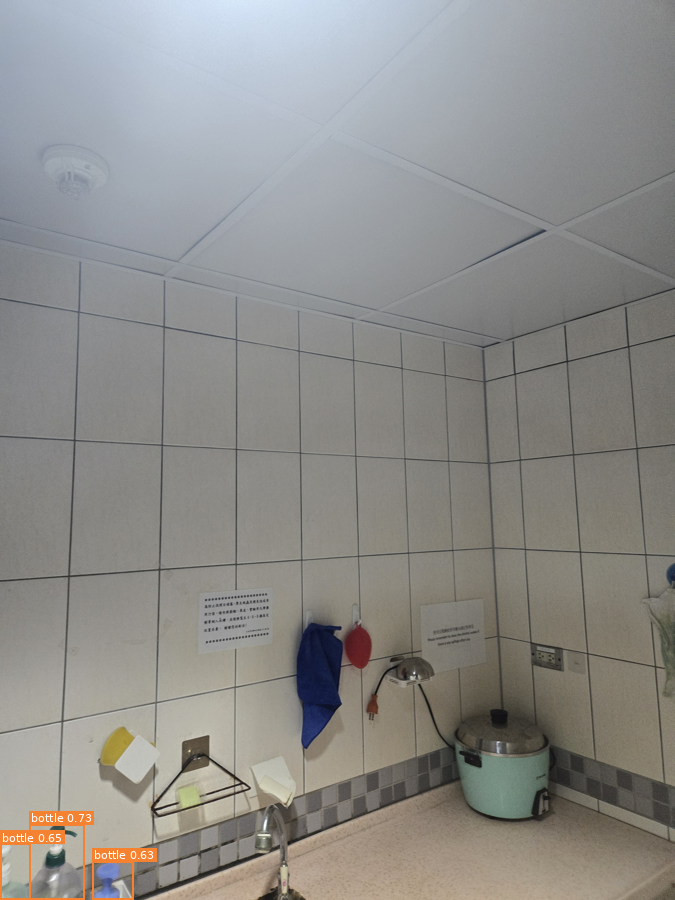

,class,confidence,"box [x1,y1,x2,y2]"
0,bottle,0.73,"[130, 3664, 376, 3998]"
1,bottle,0.65,"[0, 3751, 137, 3999]"
2,bottle,0.63,"[409, 3827, 591, 3998]"


In [ ]:
yolo = YOLO("yolo26s.pt")             # downloads the pretrained weights the first time
r = yolo.predict(photos[0], conf=0.25, verbose=False)[0]
show(r)
table(r)

In [ ]:
print(len(yolo.names), 'classes:', list(yolo.names.values()))   # everything it can ever detect

80 classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


## Lesson 2 — YOLOE-26: type what you want to find
These are the words the project uses (`ifc_kg/equipment.py`).

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 37 packages in 876ms
Prepared 2 packages in 2.66s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@7ffa84b3bfa40c42ecc1c77147a855e69cb2dd40)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


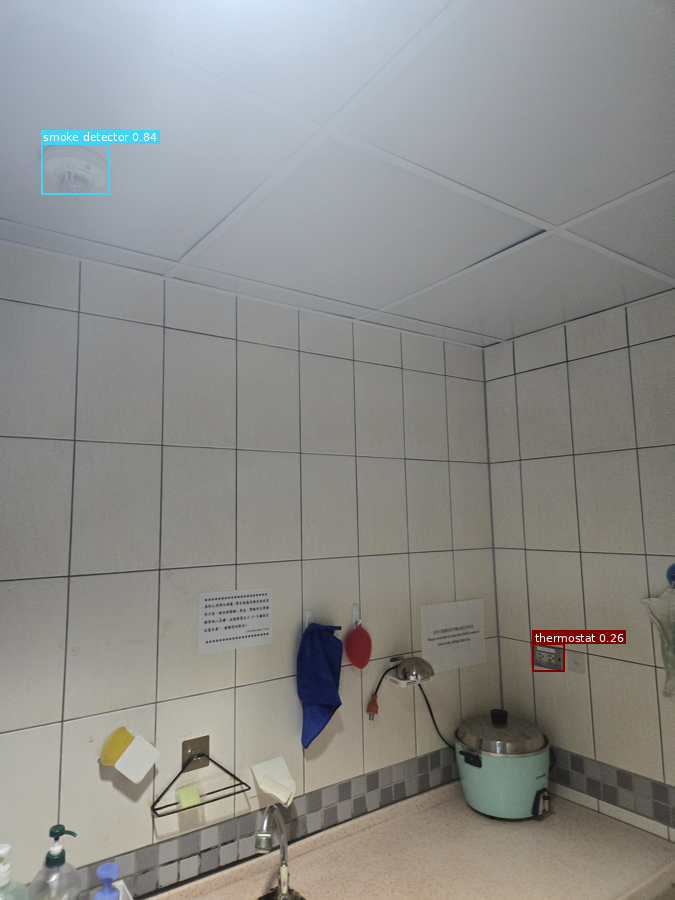

,class,confidence,"box [x1,y1,x2,y2]"
0,smoke detector,0.84,"[183, 636, 488, 863]"
1,thermostat,0.26,"[2368, 2860, 2507, 2984]"


In [ ]:
VOCAB = ["air conditioner", "ceiling air conditioning unit", "ceiling light", "fire extinguisher", "exit sign",
         "smoke detector", "fire alarm button", "fire hose cabinet", "wall speaker", "thermostat",
         "elevator door", "electrical panel", "projector", "television", "security camera",
         "door", "window", "column", "desk", "computer monitor", "person"]
world = YOLOE("yoloe-26s-seg.pt")   # first run also downloads its text encoder (~250 MB)
world.set_classes(VOCAB)
r = world.predict(photos[0], conf=0.25, verbose=False)[0]
show(r)
table(r)

**Check by eye:** which items in the photo did it miss? Which boxes are wrong?
Write them down — that is exactly what your evaluation (E2) measures.

**Optional — older vs newer open-vocabulary model.** YOLO-World (2024) on the same photo. If YOLOE-26 finds more of your equipment, that is a small result you can report.

In [ ]:
old = YOLOWorld("yolov8s-worldv2.pt"); old.set_classes(VOCAB)
for name, m in (("YOLO-World (2024)", old), ("YOLOE-26 (2026)", world)):
    r = m.predict(photos[0], conf=0.25, verbose=False)[0]
    print(f"{name:18s}", dict(Counter(r.names[int(c)] for c in r.boxes.cls)))

100%|███████████████████████████████████████| 338M/338M [00:13<00:00, 26.5MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


YOLO-World (2024)  {}
YOLOE-26 (2026)    {'smoke detector': 1, 'thermostat': 1}


## Lesson 3 — the confidence threshold
`conf` decides which boxes are kept.
- **Low** (0.1): finds more real items (**recall** ↑) but also more mistakes (**precision** ↓).
- **High** (0.5): only very sure boxes — fewer mistakes, more misses.

In [ ]:
for conf in (0.10, 0.25, 0.50):
    r = world.predict(photos[0], conf=conf, verbose=False)[0]
    print(f"conf {conf}: {len(r.boxes)} boxes ->", dict(Counter(r.names[int(c)] for c in r.boxes.cls)))

conf 0.1: 3 boxes -> {'smoke detector': 1, 'thermostat': 1, 'ceiling air conditioning unit': 1}
conf 0.25: 2 boxes -> {'smoke detector': 1, 'thermostat': 1}
conf 0.5: 1 boxes -> {'smoke detector': 1}


## Lesson 4 — image size: small things on the ceiling
YOLO shrinks every photo before looking at it (default 640 px on the long side). A 4032-px iPhone photo becomes 6× smaller, so a smoke detector becomes a few pixels.
A larger `imgsz` keeps small things visible (slower, but fine on a GPU).

imgsz 640: {'smoke detector': 1, 'thermostat': 1}
imgsz 1280: {'smoke detector': 1, 'thermostat': 2}


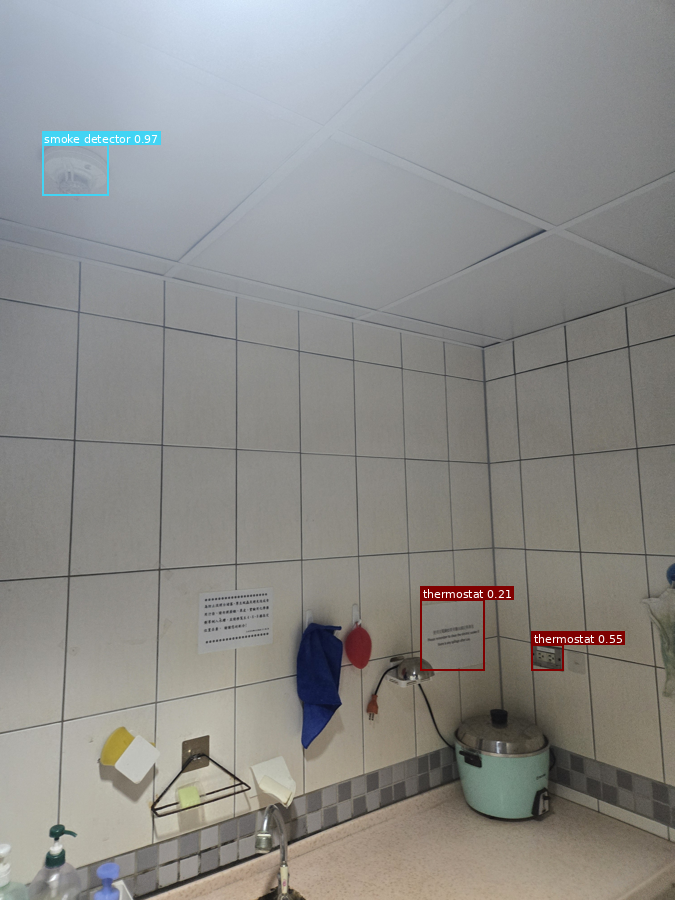

In [ ]:
for size in (640, 1280):
    r = world.predict(photos[0], conf=0.15, imgsz=size, verbose=False)[0]
    print(f"imgsz {size}:", dict(Counter(r.names[int(c)] for c in r.boxes.cls)))
r = world.predict(photos[0], conf=0.15, imgsz=1280, verbose=False)[0]
show(r)

## Lesson 5 — choosing the words (prompt engineering)
YOLO-World matches the photo against the **meaning** of your words. Different words for the same thing give different results.
Try the ceiling unit in IMG_4911 with a few names and keep the one that works best.

In [ ]:
for words in (["air conditioner"], ["ceiling air conditioning unit"], ["air vent"], ["fan coil unit"]):
    world.set_classes(words)
    r = world.predict(photos[-1], conf=0.10, imgsz=1280, verbose=False)[0]
    best = max((float(p) for p in r.boxes.conf), default=0)
    print(f"{words[0]:32s} boxes: {len(r.boxes)}  best confidence: {best:.2f}")
world.set_classes(VOCAB)   # back to the full list

air conditioner                  boxes: 0  best confidence: 0.00
ceiling air conditioning unit    boxes: 0  best confidence: 0.00
air vent                         boxes: 0  best confidence: 0.00
fan coil unit                    boxes: 0  best confidence: 0.00


## Lesson 6 — counting a room from several photos
The same light appears in all three photos. Adding them up would count it three times.
The project's rule: **for each class, take the largest number seen in any one photo.**

In [ ]:
room_count = Counter()
for p in photos:
    r = world.predict(p, conf=0.25, imgsz=1280, verbose=False)[0]
    in_photo = Counter(r.names[int(c)] for c in r.boxes.cls)
    print(p, dict(in_photo))
    for k, v in in_photo.items():
        room_count[k] = max(room_count[k], v)
print("\nRoom total (max per photo):", dict(room_count))

photos/photos_20261120_110433(0).jpg {'smoke detector': 1, 'thermostat': 1}
photos/photos_20261120_110435.jpg {'smoke detector': 1}
photos/photos_20261120_110436.jpg {'smoke detector': 1}
photos/photos_20261120_110437(0).jpg {}
photos/photos_20261120_110438.jpg {}
photos/photos_20261120_110439(0).jpg {}
photos/photos_20261120_110440.jpg {}
photos/photos_20261120_110441.jpg {}
photos/photos_20261120_110442(0).jpg {}
photos/photos_20261120_110442.jpg {}
photos/photos_20261120_110443.jpg {}
photos/photos_20261120_110444.jpg {'security camera': 1}
photos/photos_20261120_110445.jpg {}
photos/photos_20261120_110446.jpg {}
photos/photos_20261120_110533.jpg {'smoke detector': 1, 'elevator door': 1, 'door': 1}
photos/photos_20261120_110631(0).jpg {'electrical panel': 1}
photos/photos_20261120_110631.jpg {'electrical panel': 1, 'window': 1, 'ceiling light': 1}
photos/photos_20261120_110632(0).jpg {'person': 2}
photos/photos_20261120_110632.jpg {'person': 1, 'electrical panel': 1}
photos/photos_2

Compare this with what you **count by hand** in the room. Differences = the detector's errors.

## Lesson 7 — the same thing with the project
The project does Lessons 2–6 for you and compares the result with the room in the knowledge graph.
Put the unzipped `room-kg` folder in Google Drive, then:

In [ ]:
# Needs the room-kg project folder in Drive (MyDrive/room-kg)
# %cd /content/drive/MyDrive/room-kg
# !pip install -q shapely
# !python yolo_compare/compare.py --room 604 --images /content/photos/604_*.jpg --profiles outputs/room_profiles.json
# !cat outputs/observations/room_604.json

## What next
- If YOLOE-26 finds most items → keep it (no training), report its precision/recall on your survey photos.
- If it keeps missing some items (e.g. the ceiling AC unit, 消防栓) → label photos and fine-tune: the Fine-tuning section below.

# Fine-tuning
## A. Draft labels (saved in Drive)
YOLOE-26 draws its best guess. Result: `work/to_label/` in Drive with `images/`, `labels/` and `labels.txt`, plus `work/to_label.zip` (download that one for makesense.ai).
Keep only classes that really appear in your photos; label every one of them in every photo.

In [ ]:
import zipfile, shutil, random
from ultralytics import YOLO, YOLOE
CLASSES = ["ceiling light", "air conditioner", "smoke detector", "wall speaker",
           "thermostat", "computer monitor", "door", "window"]
# later, with corridor / lounge / pantry photos, add: "exit sign", "fire extinguisher", "fire hose cabinet", "security camera"

TL = WORK / "to_label"
(TL / "images").mkdir(parents=True, exist_ok=True); (TL / "labels").mkdir(parents=True, exist_ok=True)
zs = YOLOE("yoloe-26s-seg.pt"); zs.set_classes(CLASSES)
n_box = 0
for p in photos:
    img = TL / "images" / Path(p).name
    if not img.exists():
        im = Image.open(p); im.thumbnail((2048, 2048)); im.save(img, quality=92)   # smaller copy for labelling and training
    r = zs.predict(str(img), conf=0.15, imgsz=1280, verbose=False)[0]
    lines = [f"{int(c)} " + " ".join(f"{v:.5f}" for v in b.tolist()) for c, b in zip(r.boxes.cls, r.boxes.xywhn)]
    (TL / "labels" / f"{img.stem}.txt").write_text("\n".join(lines)); n_box += len(lines)
(TL / "labels" / "labels.txt").write_text("\n".join(CLASSES))
with zipfile.ZipFile(WORK / "to_label.zip", "w") as z:
    for f in TL.rglob("*"):
        if f.is_file(): z.write(f, f.relative_to(TL))
print(f"{n_box} draft boxes on {len(photos)} photos -> {WORK / 'to_label.zip'}")

110 draft boxes on 64 photos -> /content/drive/MyDrive/final project/work/to_label.zip


## Correct the boxes at www.makesense.ai (on your laptop)
1. Download `Master/ISARC 2027/work/to_label.zip` from Drive and unzip it.
2. makesense.ai → **Get Started** → drop all photos from `images/` → **Object Detection**.
3. **Load labels from file** → `labels/labels.txt` → **Start project**.
4. **Actions → Import Annotations → YOLO** → select all `.txt` files in `labels/`.
5. Fix every photo: delete wrong boxes, tighten loose ones, draw missing ones (lights!), correct wrong names.
6. **Actions → Export Annotations → YOLO** → you get a zip of `.txt` files.
7. **Upload that exported zip into `Master/ISARC 2027/work/labels_fixed/` in Drive.** (Not the photos zip.)

## B. Build the dataset from your corrected labels

In [ ]:
# Works on its own after a restart: run Setup + Google Drive folders first, then this cell.
import zipfile, shutil, random
from pathlib import Path
from collections import Counter
CLASSES = ["ceiling light", "air conditioner", "smoke detector", "wall speaker",
           "thermostat", "computer monitor", "door", "window"]       # must be the same list (and order) as Cell A
TL = WORK / "to_label"

FIX = WORK / "labels_fixed"
FIX.mkdir(exist_ok=True)
for z in FIX.glob("*.zip"):                              # unzip the makesense export if it is still zipped
    with zipfile.ZipFile(z) as zz: zz.extractall(FIX / z.stem)
txt = {p.stem: p for p in FIX.rglob("*.txt") if p.name not in ("labels.txt", "classes.txt")}
images = sorted((TL / "images").glob("*.jpg"))
assert txt, f"No label files in {FIX}. Put the zip exported from makesense.ai there (not the photos zip)."
bad = [p.name for p in txt.values() for l in p.read_text().splitlines() if l.strip() and int(l.split()[0]) >= len(CLASSES)]
assert not bad, f"Class numbers higher than CLASSES allows in {bad[:3]}: was the same labels.txt loaded in makesense?"
print(len(txt), "label files for", len(images), "photos;", sum(i.stem not in txt for i in images), "photos without labels (treated as empty)")

ds = Path("dataset"); shutil.rmtree(ds, ignore_errors=True)
pairs = [(i, txt.get(i.stem)) for i in images]; random.Random(0).shuffle(pairs); k = max(1, round(len(pairs) * 0.2))
for split, part in (("val", pairs[:k]), ("train", pairs[k:])):
    (ds / "images" / split).mkdir(parents=True); (ds / "labels" / split).mkdir(parents=True)
    for img, lab in part:
        shutil.copy(img, ds / "images" / split / img.name)
        (ds / "labels" / split / f"{img.stem}.txt").write_text(lab.read_text() if lab else "")
(ds / "data.yaml").write_text("\n".join([f"path: {ds.resolve()}", "train: images/train", "val: images/val", "names:"]
                                          + [f"  {i}: {c}" for i, c in enumerate(CLASSES)]))
count = Counter(int(l.split()[0]) for p in (ds / "labels/train").glob("*.txt") for l in p.read_text().splitlines() if l.strip())
print(f"train {len(pairs) - k} photos, val {k} photos. Boxes per class in train:")
for i, c in enumerate(CLASSES): print(f"  {count[i]:4d}  {c}" + ("   <- few: weak" if count[i] < 15 else ""))

AssertionError: No label files in /content/drive/MyDrive/final project/work/labels_fixed. Put the zip exported from makesense.ai there (not the photos zip).

## C. Train (GPU: Runtime → Change runtime type → L4 or T4)
The trained model is saved in Drive: `work/runs/ft/weights/best.pt`. With L4 you can use `batch=16`; if you get *CUDA out of memory*, use `batch=4`.

In [ ]:
from ultralytics import YOLO
import torch; assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> L4 or T4"
model = YOLO("yolo26s.pt")
model.train(data="dataset/data.yaml", epochs=100, imgsz=1280, batch=8, patience=30,
            project=str(WORK / "runs"), name="ft", exist_ok=True, seed=0)

## D. Zero-shot vs fine-tuned

In [ ]:
# Cell D: zero-shot vs fine-tuned, scored the same way on the validation photos.
# A predicted box counts as "found" if it has the right class and overlaps a box you drew by >= 50% (IoU 0.5).
from ultralytics import YOLO, YOLOE
from pathlib import Path
from collections import Counter

VAL = Path("dataset/images/val")

def gt_boxes(img):
    w, h = Image.open(img).size
    out = []
    for l in (Path("dataset/labels/val") / f"{img.stem}.txt").read_text().splitlines():
        if l.strip():
            c, x, y, bw, bh = map(float, l.split())
            out.append((int(c), (x - bw / 2) * w, (y - bh / 2) * h, (x + bw / 2) * w, (y + bh / 2) * h))
    return out

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

def evaluate(model, conf=0.25):
    tp, fp, fn = Counter(), Counter(), Counter()
    for img in sorted(VAL.glob("*.jpg")):
        gt, used = gt_boxes(img), set()
        r = model.predict(str(img), conf=conf, imgsz=1280, verbose=False)[0]
        preds = sorted(zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist()), key=lambda t: -t[1])
        for c, p, b in preds:
            best_j, best = None, 0.5
            for j, g in enumerate(gt):
                if j not in used and g[0] == int(c) and iou(b, g[1:]) >= best:
                    best_j, best = j, iou(b, g[1:])
            if best_j is None: fp[int(c)] += 1
            else: tp[int(c)] += 1; used.add(best_j)
        for j, g in enumerate(gt):
            if j not in used: fn[g[0]] += 1
    T, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    P = T / (T + FP) if T + FP else 0; R = T / (T + FN) if T + FN else 0
    total = {"precision": round(P, 2), "recall": round(R, 2), "F1": round(2 * P * R / (P + R), 2) if P + R else 0}
    per = pd.DataFrame({name: {"in photos": tp[i] + fn[i], "found": tp[i], "missed": fn[i], "wrong boxes": fp[i]}
                        for i, name in enumerate(CLASSES)}).T
    return total, per

best = YOLO(str(WORK / "runs/ft/weights/best.pt"))
zs = YOLOE("yoloe-26s-seg.pt"); zs.set_classes(CLASSES)
z_total, z_per = evaluate(zs)
f_total, f_per = evaluate(best)

print(pd.DataFrame([z_total, f_total], index=["zero-shot YOLOE-26", "fine-tuned YOLO26"]), "\n")
print("Per class (zero-shot | fine-tuned):")
print(pd.concat({"zero-shot": z_per, "fine-tuned": f_per}, axis=1), "\n")

for f in ["results.png", "confusion_matrix_normalized.png"]:
    p = WORK / "runs/ft" / f
    if p.exists(): im = Image.open(p); im.thumbnail((900, 900)); display(im)
img = sorted(VAL.glob("*.jpg"))[0]
print("zero-shot:");  show(zs.predict(str(img), conf=0.25, imgsz=1280, verbose=False)[0])
print("fine-tuned:"); show(best.predict(str(img), conf=0.25, imgsz=1280, verbose=False)[0])

## E. Your model
Already saved in Drive — nothing to download. Copy it into the project when you need it:

In [ ]:
print(WORK / "runs/ft/weights/best.pt")
# in the room-kg project: python yolo_compare/compare.py --room 604 --images ... --model <that path>

In [ ]:
# F. Room 604: your model's detections compared with the room in the IFC knowledge graph
import sys, json, zipfile
from pathlib import Path
RK = Path("/content/drive/MyDrive/Master/ISARC 2027/room-kg.zip")
if not RK.exists():
    with zipfile.ZipFile(BASE / "room-kg.zip") as z: z.extractall("/content")
sys.path[:0] = [str(RK), str(RK / "yolo_compare")]
import compare

profile = compare.find_profile(json.loads((RK / "outputs/room_profiles.json").read_text(encoding="utf-8")), "604")
imgs = sorted((WORK / "to_label/images").glob("604_*.jpg"))
per_photo = [compare.detect(str(p), model_name=str(WORK / "runs/ft/weights/best.pt")) for p in imgs]
res = compare.compare_room(per_photo, profile)

print("Room:", profile["display_name"], "\n")
print("Seen in photos AND in the IFC: ", res["matched"])
print("In the IFC, not seen in photos:", res["missing_from_photo"])
print("Seen in photos, NOT in the IFC (proposals to add):")
for p in res["proposals"]:
    print(f"   {p['label']:25s} x{p['count']}   confidence {p['confidence']:.2f}   best photo {imgs[p['evidence']['photo']].name}")
(WORK / "room_604.json").write_text(json.dumps({**res, "images": [i.name for i in imgs], "detections": per_photo}, indent=1))